# 02.2 · CNN + PSD 

## 1. Importy i konfiguracja

In [11]:
from pathlib import Path
import json
import gc
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
)
from IPython.display import display

print('MNE:', mne.__version__, '| TensorFlow:', tf.__version__)

MNE: 1.9.0 | TensorFlow: 2.18.0


In [ ]:
TRYB_TESTOWY = False
USE_ICA = True
USE_ALL_64_CHANNELS = True
ROOT = Path.cwd()
TAG = ('ica' if USE_ICA else 'bez_ica') + ('_64ch' if USE_ALL_64_CHANNELS else '_19ch')
DATA_DIR = ROOT / (('benchmark_data_demo_' if TRYB_TESTOWY else 'benchmark_data_') + TAG)
RESULTS_BASE = ROOT / (('results_demo_' if TRYB_TESTOWY else 'results_') + TAG)

VARIANTS = ['raw', 'psd', 'fusion']
VARIANT_NAMES = {'raw':'CNN-czas', 'psd':'CNN-PSD', 'fusion':'CNN-czas+PSD'}
VARIANT_DIRS = {'raw':'cnn_raw', 'psd':'cnn_psd', 'fusion':'cnn_psd_fusion'}

FOLDS_TO_RUN = [1] if TRYB_TESTOWY else [1, 2, 3, 4, 5]
MAX_EPOCHS = 20 if TRYB_TESTOWY else 200  
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
SEED = 42
THRESHOLD = 0.5             
DROPOUT = 0.5
EARLY_PATIENCE = 25
LR_PATIENCE = 10

LOSS_MODE = 'focal'  # 'binary_crossentropy' lub 'focal'
FOCAL_GAMMA = 2.0
FOCAL_ALPHA = 0.5
USE_CLASS_WEIGHTS = False
USE_AUGMENTATION = False
AUG_PROBABILITY = 0.5
AUG_REL_NOISE = 0.05   
AUG_MAX_SHIFT = 20
AUG_SCALE_RANGE = (0.9, 1.1)

PSD_FMIN, PSD_FMAX = 8., 30.
PSD_N_PER_SEG = 160 
PSD_N_FFT = 256      
PSD_N_OVERLAP = 80
PSD_BATCH_SIZE = 96

print('Dane:', DATA_DIR)
print('Foldy:', FOLDS_TO_RUN, '| Warianty:', VARIANTS)
print('Focal loss:', LOSS_MODE, '| Augmentacja:', USE_AUGMENTATION,
      '| Wagi klas:', USE_CLASS_WEIGHTS)

Dane: /home/eliza/mgr-phd/benchmark_data_ica_64ch
Foldy: [1, 2, 3, 4, 5] | Warianty: ['fusion']
Focal loss: focal | Augmentacja: False | Wagi klas: False


## 2. Wspólne wejście z notebooka 01

In [13]:
required_paths = [DATA_DIR / f for f in ['epochs.npz','splits.npz','manifest.json']]
for path in required_paths:
    if not path.is_file():
        raise FileNotFoundError(f'Brak {path}. Najpierw wykonaj notebook 01.')
with np.load(DATA_DIR / 'epochs.npz', allow_pickle=False) as dataset:
    X = dataset['X'].astype(np.float32, copy=False)
    y = dataset['y'].astype(np.uint8, copy=False)
    subjects = dataset['subjects'].astype(str)
    trial_ids = dataset['trial_ids'].astype(str)
    channel_names = dataset['channel_names'].tolist()
with np.load(DATA_DIR / 'splits.npz', allow_pickle=False) as data_splits:
    splits = {k: data_splits[k] for k in data_splits.files}
manifest = json.loads((DATA_DIR/'manifest.json').read_text(encoding='utf-8'))
assert manifest['demo_mode'] == TRYB_TESTOWY, 'Inny TRYB_TESTOWY niż w 01'
assert bool(manifest['ica']) == bool(USE_ICA), 'Inne ICA niż w 01'
assert manifest['channel_mode'] == ('64' if USE_ALL_64_CHANNELS else '19')
assert manifest['units'] == 'microvolts', 'Oczekiwano epok w µV'
assert X.ndim == 3 and X.shape[1] == len(channel_names)
assert len(X) == len(y) == len(subjects) == len(trial_ids)
assert len(np.unique(trial_ids)) == len(trial_ids)
assert set(np.unique(y)) == {0,1}
assert all(np.isfinite(X.reshape(-1)[::max(1, X.size//10000)]))
assert np.isclose(float(manifest['sampling_rate_hz']), 160.)
assert X.shape[2] == 481
assert set(VARIANTS).issubset({'raw','psd','fusion'}) and len(VARIANTS)==len(set(VARIANTS))
assert sorted(set(FOLDS_TO_RUN)) == sorted(FOLDS_TO_RUN)
assert all(isinstance(f, int) and 1 <= f <= 5 for f in FOLDS_TO_RUN)
assert LOSS_MODE in {'binary_crossentropy','focal'}
assert 0 <= AUG_PROBABILITY <= 1

for fold in FOLDS_TO_RUN:
    tr, va, te = (splits[f'{p}_{fold}'] for p in ('train','val','test'))
    assert all(np.unique(idx).size == len(idx) for idx in (tr,va,te))
    assert not (set(tr)&set(va) or set(tr)&set(te) or set(va)&set(te))
    people = [set(subjects[idx]) for idx in (tr,va,te)]
    assert not (people[0]&people[1] or people[0]&people[2] or people[1]&people[2])
    assert all(set(np.unique(y[idx])) == {0,1} for idx in (tr,va,te))

print('X (epoki, kanały, czas):', X.shape, '| jednostka: µV')
print('Uczestników:', len(np.unique(subjects)), '| liczebności klas:', np.bincount(y))
print('Kanały:', channel_names)
print('Podziały z notebooka 01: OK')

X (epoki, kanały, czas): (9844, 64, 481) | jednostka: µV
Uczestników: 109 | liczebności klas: [4894 4950]
Kanały: ['FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP5', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'CP6', 'Fp1', 'Fpz', 'Fp2', 'AF7', 'AF3', 'AFz', 'AF4', 'AF8', 'F7', 'F5', 'F3', 'F1', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT7', 'FT8', 'T7', 'T8', 'T9', 'T10', 'TP7', 'TP8', 'P7', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'P8', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'Oz', 'O2', 'Iz']
Podziały z notebooka 01: OK


## 3. PSD Welcha i wizualizacja

PSD: (9844, 64, 36) | częstotliwości: 8.125 – 30.0 Hz


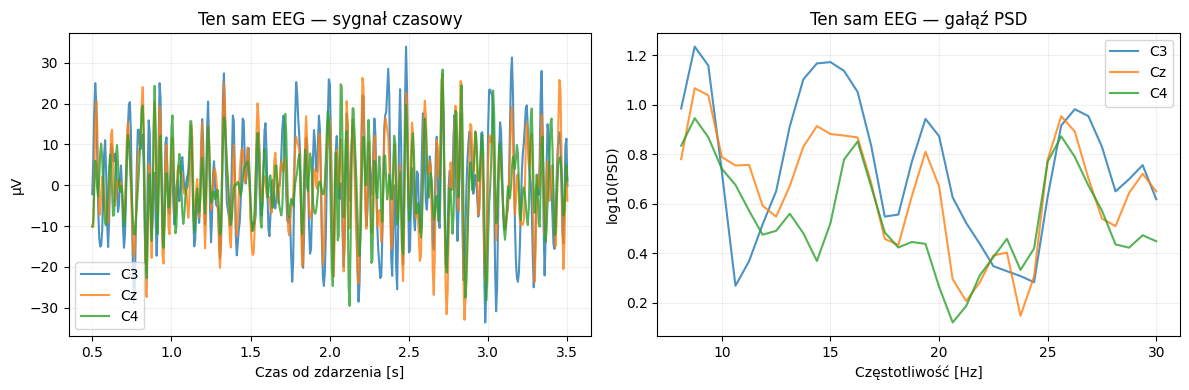

In [14]:
from mne.time_frequency import psd_array_welch

def compute_log_psd(X_input, sfreq=160.0, batch_size=96):
    """X_input: (epoki, kanały, próbki), w µV. Wynik: log10 PSD, (epoki, kanały, częstotliwości)."""
    X_input = np.asarray(X_input)
    assert X_input.ndim == 3 and X_input.shape[-1] >= PSD_N_PER_SEG
    if PSD_N_OVERLAP >= PSD_N_PER_SEG or PSD_N_PER_SEG > PSD_N_FFT:
        raise ValueError('Niepoprawna konfiguracja parametrów Welcha')
    chunks = []
    frequencies = None
    for start in range(0, len(X_input), batch_size):
        batch_psd, freq = psd_array_welch(
            X_input[start:start+batch_size], sfreq=sfreq,
            fmin=PSD_FMIN, fmax=PSD_FMAX,
            n_fft=PSD_N_FFT, n_per_seg=PSD_N_PER_SEG,
            n_overlap=PSD_N_OVERLAP, average='mean', window='hann',
            verbose='ERROR',
        )
        if frequencies is not None:
            assert np.array_equal(frequencies, freq)
        frequencies = freq
        chunks.append(np.log10(np.maximum(batch_psd, 1e-12)).astype(np.float32))
    return np.concatenate(chunks, axis=0), frequencies

# PSD liczymy raz dla tych samych próbek; podział trening/test nie wpływa na wynik Welcha.
X_psd, psd_freqs = compute_log_psd(X, sfreq=manifest['sampling_rate_hz'], batch_size=PSD_BATCH_SIZE)
assert X_psd.shape[:2] == X.shape[:2]
assert X_psd.shape[2] >= 8
print('PSD:', X_psd.shape, '| częstotliwości:', psd_freqs[0], '–', psd_freqs[-1], 'Hz')

idx = 0
show_channels = [ch for ch in ('C3','Cz','C4') if ch in channel_names]
fig, axs = plt.subplots(1, 2, figsize=(12,4))
time_axis = np.arange(X.shape[2]) / float(manifest['sampling_rate_hz']) + 0.5
for ch in show_channels:
    c = channel_names.index(ch)
    axs[0].plot(time_axis, X[idx,c], label=ch, alpha=.8)
    axs[1].plot(psd_freqs, X_psd[idx,c], label=ch, alpha=.8)
axs[0].set(xlabel='Czas od zdarzenia [s]', ylabel='µV', title='Ten sam EEG — sygnał czasowy')
axs[1].set(xlabel='Częstotliwość [Hz]', ylabel='log10(PSD)', title='Ten sam EEG — gałąź PSD')
for ax in axs: ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## 4. Normalizacja i opcjonalna augmentacja — zawsze tylko trening

In [ ]:
def normalize_raw_fold(train, val, test):
    mean = train.mean(axis=(0,2), keepdims=True)
    std = train.std(axis=(0,2), keepdims=True)
    std = np.where(std < 1e-6, 1.0, std)
    transform = lambda a: ((a - mean) / std).astype(np.float32)[...,None]
    return transform(train), transform(val), transform(test), mean, std

def normalize_psd_fold(train, val, test):
    mean = train.mean(axis=0, keepdims=True)
    std = train.std(axis=0, keepdims=True)
    std = np.where(std < 1e-6, 1.0, std)
    transform = lambda a: ((a - mean) / std).astype(np.float32)[...,None]
    return transform(train), transform(val), transform(test), mean, std

def augment_train_only(x_train, y_train, seed, probability=0.5):
    rng = np.random.default_rng(seed)
    chosen = np.flatnonzero(rng.random(len(y_train)) < probability)
    if not len(chosen):
        return x_train, y_train, 0
    channel_std = np.maximum(x_train.std(axis=(0,2), keepdims=True), 1e-3)
    extra = x_train[chosen].copy()
    extra += rng.normal(0, 1., extra.shape).astype(np.float32) * (AUG_REL_NOISE*channel_std)
    for i in range(len(extra)):
        shift = int(rng.integers(-AUG_MAX_SHIFT, AUG_MAX_SHIFT+1))
        if shift > 0:
            extra[i,:,shift:] = extra[i,:,:-shift].copy()
            extra[i,:,:shift] = extra[i,:,shift:shift+1]  
        elif shift < 0:
            k = -shift
            extra[i,:,:-k] = extra[i,:,k:].copy()
            extra[i,:,-k:] = extra[i,:,-k-1:-k]
        extra[i] *= float(rng.uniform(*AUG_SCALE_RANGE))
    return (np.concatenate([x_train, extra], axis=0),
            np.concatenate([y_train, y_train[chosen]]), len(extra))

first_fold = FOLDS_TO_RUN[0]
tr, va, te = (splits[f'{part}_{first_fold}'] for part in ('train','val','test'))
print('Fold',first_fold)
for name, idx in [('Train',tr),('Validation',va),('Test',te)]:
    print(name, 'epok:',len(idx),'osób:',len(np.unique(subjects[idx])), 'klasy:',np.bincount(y[idx]))

Fold 1
Train epok: 6241 osób: 69 klasy: [3106 3135]
Validation epok: 1617 osób: 18 klasy: [803 814]
Test epok: 1986 osób: 22 klasy: [ 985 1001]


## 5. Twoja architektura: trzy warianty ablacyjne

In [ ]:
def branch_raw(x_in, n_channels, dropout=0.5):
    x = layers.Conv2D(8, (1,64), padding='same', use_bias=False, name='raw_conv')(x_in)
    x = layers.BatchNormalization(name='raw_bn1')(x)
    x = layers.DepthwiseConv2D((n_channels,1), depth_multiplier=2,
                               use_bias=False, padding='valid', name='raw_depthwise')(x)
    x = layers.BatchNormalization(name='raw_bn2')(x)
    x = layers.Activation('elu', name='raw_elu1')(x)
    x = layers.AveragePooling2D((1,4), name='raw_pool1')(x)
    x = layers.Dropout(dropout, name='raw_drop1')(x)
    x = layers.SeparableConv2D(16, (1,16), use_bias=False,
                               padding='same', name='raw_separable')(x)
    x = layers.BatchNormalization(name='raw_bn3')(x)
    x = layers.Activation('elu', name='raw_elu2')(x)
    x = layers.AveragePooling2D((1,8), name='raw_pool2')(x)
    x = layers.Dropout(dropout, name='raw_drop2')(x)
    return layers.Flatten(name='raw_flatten')(x)

def branch_psd(x_in, n_channels, dropout=0.5):
    x = layers.Conv2D(8, (1,5), padding='same', use_bias=False, name='psd_conv')(x_in)
    x = layers.BatchNormalization(name='psd_bn1')(x)
    x = layers.DepthwiseConv2D((n_channels,1), depth_multiplier=2,
                               use_bias=False, padding='valid', name='psd_depthwise')(x)
    x = layers.BatchNormalization(name='psd_bn2')(x)
    x = layers.Activation('elu', name='psd_elu1')(x)
    x = layers.AveragePooling2D((1,2), name='psd_pool1')(x)
    x = layers.Dropout(dropout, name='psd_drop1')(x)
    x = layers.SeparableConv2D(16, (1,7), use_bias=False,
                               padding='same', name='psd_separable')(x)
    x = layers.BatchNormalization(name='psd_bn3')(x)
    x = layers.Activation('elu', name='psd_elu2')(x)
    x = layers.AveragePooling2D((1,2), name='psd_pool2')(x)
    x = layers.Dropout(dropout, name='psd_drop2')(x)
    return layers.Flatten(name='psd_flatten')(x)

def binary_focal_loss(gamma=2., alpha=0.75):
    def focal(y_true, y_pred):
        y_true = tf.cast(tf.reshape(y_true, (-1,)), tf.float32)
        y_pred = tf.cast(tf.reshape(y_pred, (-1,)), tf.float32)
        bce = keras.backend.binary_crossentropy(y_true, y_pred)
        p_t = y_true * y_pred + (1-y_true)*(1-y_pred)
        alpha_t = y_true * alpha + (1-y_true)*(1-alpha)
        return tf.reduce_mean(alpha_t * tf.pow(1-p_t, gamma) * bce)
    return focal

def build_my_cnn(variant, n_channels, n_times, n_freqs, dropout=0.5,
                 loss_mode='binary_crossentropy'):
    if variant not in VARIANT_NAMES:
        raise ValueError(f'Nieznany wariant: {variant}')
    inputs = []
    features = []
    if variant in ('raw','fusion'):
        input_raw = keras.Input(shape=(n_channels,n_times,1), name='raw')
        inputs.append(input_raw)
        features.append(branch_raw(input_raw, n_channels, dropout))
    if variant in ('psd','fusion'):
        input_psd = keras.Input(shape=(n_channels,n_freqs,1), name='psd')
        inputs.append(input_psd)
        features.append(branch_psd(input_psd, n_channels, dropout))
    x = layers.Concatenate(name='fusion_concat')(features) if len(features)==2 else features[0]
    x = layers.Dense(64, activation='elu', name='fusion_dense_64')(x)
    x = layers.Dropout(dropout, name='fusion_dropout')(x)
    outputs = layers.Dense(1, activation='sigmoid', name='p_left')(x)
    model = keras.Model(inputs=inputs, outputs=outputs, name=VARIANT_DIRS[variant])
    loss = ('binary_crossentropy' if loss_mode=='binary_crossentropy'
            else binary_focal_loss(FOCAL_GAMMA, FOCAL_ALPHA))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=loss,
        metrics=[keras.metrics.BinaryAccuracy(name='accuracy'), keras.metrics.AUC(name='auc')],
    )
    return model

for variant in VARIANTS:
    preview = build_my_cnn(variant, X.shape[1], X.shape[2], X_psd.shape[2],
                           dropout=DROPOUT, loss_mode=LOSS_MODE)
    print(f'{VARIANT_NAMES[variant]}: {preview.count_params():,} parametrów')
    preview.summary()
    del preview
keras.backend.clear_session()

CNN-czas+PSD: 28,505 parametrów


Model: "cnn_psd_fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ raw (InputLayer)    │ (None, 64, 481,   │          0 │ -                 │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ psd (InputLayer)    │ (None, 64, 36, 1) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ raw_conv (Conv2D)   │ (None, 64, 481,   │        512 │ raw[0][0]         │
│                     │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ psd_conv (Conv2D)   │ (None, 64, 36, 8) │         40 │ psd[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ raw_bn1             │ (None, 64, 481,   │         32 │ raw_conv[0][0]    │
│ (BatchNormalizatio… │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ psd_bn1             │ (None, 64, 36, 8) │         32 │ psd_conv[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ raw_depthwise       │ (None, 1, 481,    │      1,024 │ raw_bn1[0][0]     │
│ (DepthwiseConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ psd_depthwise       │ (None, 1, 36, 16) │      1,024 │ psd_bn1[0][0]     │
│ (DepthwiseConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ raw_bn2             │ (None, 1, 481,    │         64 │ raw_depthwise[0]… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ psd_bn2             │ (None, 1, 36, 16) │         64 │ psd_depthwise[0]… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ raw_elu1            │ (None, 1, 481,    │          0 │ raw_bn2[0][0]     │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ psd_elu1            │ (None, 1, 36, 16) │          0 │ psd_bn2[0][0]     │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ raw_pool1           │ (None, 1, 120,    │          0 │ raw_elu1[0][0]    │
│ (AveragePooling2D)  │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ psd_pool1           │ (None, 1, 18, 16) │          0 │ psd_elu1[0][0]    │
│ (AveragePooling2D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ raw_drop1 (Dropout) │ (None, 1, 120,    │          0 │ raw_pool1[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ psd_drop1 (Dropout) │ (None, 1, 18, 16) │          0 │ psd_pool1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ raw_separable       │ (None, 1, 120,    │        512 │ raw_drop1[0][0]   │
│ (SeparableConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ psd_separable       │ (None, 1, 18, 16) │        368 │ psd_drop1[0][0] 

 Total params: 28,505 (111.35 KB)

 Trainable params: 28,345 (110.72 KB)

 Non-trainable params: 160 (640.00 B)

## 6. Funkcje oceny — zawsze z rzeczywistych predykcji

In [ ]:
def score_predictions(y_true, p_left, threshold=0.5):
    guess = (np.asarray(p_left) >= threshold).astype(np.uint8)
    return {
        'roc_auc': float(roc_auc_score(y_true,p_left)),
        'average_precision': float(average_precision_score(y_true,p_left)),
        'accuracy': float(accuracy_score(y_true,guess)),
        'balanced_accuracy': float(balanced_accuracy_score(y_true,guess)),
        'precision': float(precision_score(y_true,guess,zero_division=0)),
        'recall': float(recall_score(y_true,guess,zero_division=0)),
        'f1': float(f1_score(y_true,guess,zero_division=0)),
    }

def model_inputs(variant, X_raw, X_psd):
    if variant=='raw':return X_raw
    if variant=='psd':return X_psd
    if variant=='fusion':return [X_raw, X_psd]
    raise ValueError(variant)


## 7. Trening: te same foldy co EEGNet, osobny model dla każdego wariantu

In [ ]:
keras.utils.set_random_seed(SEED)
all_predictions = {variant:[] for variant in VARIANTS}
fold_metrics = {variant:[] for variant in VARIANTS}
histories = {variant:{} for variant in VARIANTS}
params_by_variant = {}

for fold in FOLDS_TO_RUN:
    print('\n'+'='*22+f' FOLD {fold} '+'='*22)
    tr, va, te = (splits[f'{part}_{fold}'] for part in ('train','val','test'))

    X_train_base = X[tr]
    Y_train = y[tr]
    if USE_AUGMENTATION:
        X_train_base, Y_train, n_aug = augment_train_only(
            X_train_base, Y_train, seed=SEED+fold, probability=AUG_PROBABILITY)
        print(f'Augmentacja: +{n_aug} epok tylko w treningu')
        psd_train_base, freqs_aug = compute_log_psd(X_train_base, sfreq=manifest['sampling_rate_hz'],
                                                      batch_size=PSD_BATCH_SIZE)
        assert np.array_equal(freqs_aug, psd_freqs)
    else:
        psd_train_base = X_psd[tr]

    X_train_raw, X_val_raw, X_test_raw, raw_mu, raw_std = normalize_raw_fold(
        X_train_base, X[va], X[te])
    X_train_psd, X_val_psd, X_test_psd, psd_mu, psd_std = normalize_psd_fold(
        psd_train_base, X_psd[va], X_psd[te])
    print('Czas:',X_train_raw.shape,'PSD:', X_train_psd.shape, 'Test:', len(te))

    class_weights = None
    if USE_CLASS_WEIGHTS:
        class_count = np.bincount(Y_train.astype(int), minlength=2)
        assert class_count.min() > 0
        class_weights = {k:float(len(Y_train)/(2*class_count[k])) for k in (0,1)}
        print('Wagi klas (tylko trening):',class_weights)

    for variant in VARIANTS:
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED+fold)  
        out = RESULTS_BASE / VARIANT_DIRS[variant]
        fold_out = out / f'fold_{fold}'
        fold_out.mkdir(parents=True,exist_ok=True)
        if variant in ('raw','fusion'):
            np.savez_compressed(fold_out/'normalizer_raw.npz', mean=raw_mu, std=raw_std)
        if variant in ('psd','fusion'):
            np.savez_compressed(fold_out/'normalizer_psd.npz', mean=psd_mu, std=psd_std,
                                freqs=psd_freqs)

        network = build_my_cnn(variant, X.shape[1], X.shape[2], X_psd.shape[2],
                               DROPOUT, LOSS_MODE)
        params_by_variant[variant] = network.count_params()
        train_input = model_inputs(variant, X_train_raw, X_train_psd)
        val_input = model_inputs(variant, X_val_raw, X_val_psd)
        test_input = model_inputs(variant, X_test_raw, X_test_psd)
        print(f'    {VARIANT_NAMES[variant]} ({network.count_params():,} parametrów)')
        history = network.fit(
            train_input, Y_train, validation_data=(val_input, y[va]),
            epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, shuffle=True,
            class_weight=class_weights,
            callbacks=[
                keras.callbacks.EarlyStopping(monitor='val_auc', mode='max',
                                              patience=EARLY_PATIENCE, restore_best_weights=True),
                keras.callbacks.ReduceLROnPlateau(monitor='val_auc', mode='max',
                                                  factor=.5, patience=LR_PATIENCE, min_lr=1e-5),
                keras.callbacks.CSVLogger(str(fold_out/'training.csv')),
            ], verbose=1,
        )
        histories[variant][fold] = history.history
        network.save(fold_out/'model.keras')

        proba = network.predict(test_input, batch_size=BATCH_SIZE, verbose=0).reshape(-1)
        measured = score_predictions(y[te], proba, threshold=THRESHOLD)
        fold_metrics[variant].append({'fold':int(fold),'n_test':int(len(te)),
                                      'n_train_after_aug':int(len(Y_train)), **measured})
        print('    TEST:', {k:round(v,4) for k,v in measured.items()})
        for pos,p in zip(te,proba):
            all_predictions[variant].append({
                'model': VARIANT_NAMES[variant], 'fold': int(fold),
                'trial_id':str(trial_ids[pos]), 'subject':str(subjects[pos]),
                'y_true':int(y[pos]), 'p_left':float(p),
            })
        pd.DataFrame(all_predictions[variant]).to_csv(out/'out_of_fold_predictions.csv', index=False)
        pd.DataFrame(fold_metrics[variant]).to_csv(out/'fold_metrics.csv', index=False)
        del network, train_input, val_input, test_input, proba
        gc.collect()

    del X_train_base, psd_train_base
    del X_train_raw, X_val_raw, X_test_raw, X_train_psd, X_val_psd, X_test_psd
    gc.collect()

print('Koniec treningów:')
for variant in VARIANTS:
    print(VARIANT_NAMES[variant], RESULTS_BASE/VARIANT_DIRS[variant]/'out_of_fold_predictions.csv')


====================== FOLD 1 ======================
Czas: (6241, 64, 481, 1) PSD: (6241, 64, 36, 1) Test: 1986
    CNN-czas+PSD (28,505 parametrów)
Epoch 1/200
196/196 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.4921 - auc: 0.4974 - loss: 0.1750 - val_accuracy: 0.5040 - val_auc: 0.5211 - val_loss: 0.0869 - learning_rate: 0.0010
Epoch 2/200
196/196 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.5085 - auc: 0.5085 - loss: 0.1088 - val_accuracy: 0.5232 - val_auc: 0.5431 - val_loss: 0.0865 - learning_rate: 0.0010
Epoch 3/200
196/196 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.5106 - auc: 0.5155 - loss: 0.0969 - val_accuracy: 0.5325 - val_auc: 0.5563 - val_loss: 0.0862 - learning_rate: 0.0010
Epoch 4/200
196/196 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.5075 - auc: 0.5151 - loss: 0.0918 - val_accuracy: 0.5702 - val_auc: 0.5913 - val_loss: 0.0854 - learning_rate: 0.0010
Epoch 5/200
196/196 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.5161 - auc: 0.5226 - loss: 0.0888 - v

## 8. Historia treningu i macierze pomyłek

Wybierz fold na wykresie. Wykresy zbiorcze i pełne porównanie z EEGNet znajdziesz w **03**.

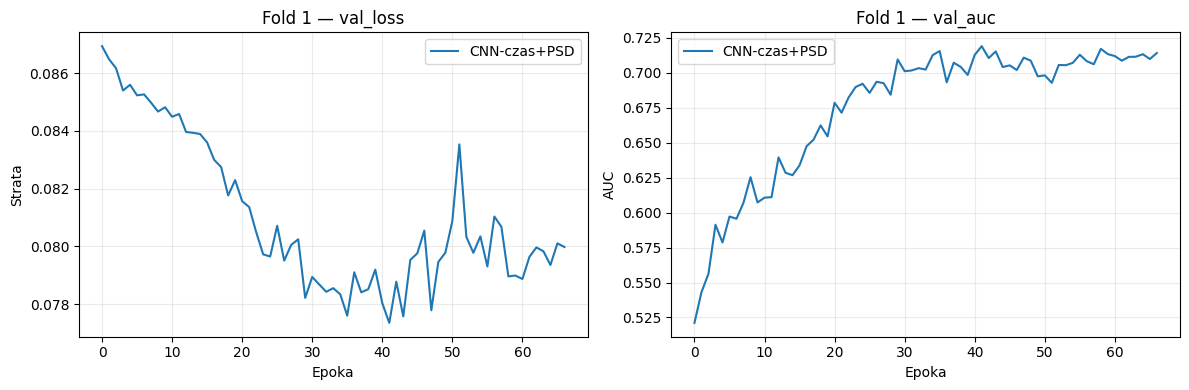

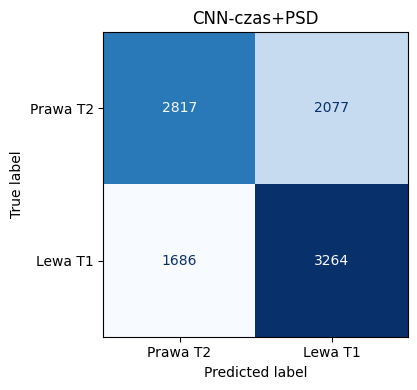

In [19]:
SHOW_FOLD = FOLDS_TO_RUN[0]
fig, axes = plt.subplots(1,2,figsize=(12,4))
for variant in VARIANTS:
    history = histories[variant][SHOW_FOLD]
    axes[0].plot(history['val_loss'], label=VARIANT_NAMES[variant])
    axes[1].plot(history['val_auc'], label=VARIANT_NAMES[variant])
axes[0].set(title=f'Fold {SHOW_FOLD} — val_loss',xlabel='Epoka',ylabel='Strata')
axes[1].set(title=f'Fold {SHOW_FOLD} — val_auc',xlabel='Epoka',ylabel='AUC')
for ax in axes:ax.legend();ax.grid(alpha=.25)
plt.tight_layout();plt.show()

fig, axes = plt.subplots(1,len(VARIANTS),figsize=(5*len(VARIANTS),4))
for ax,variant in zip(np.atleast_1d(axes),VARIANTS):
    frame = pd.DataFrame(all_predictions[variant])
    result = confusion_matrix(frame['y_true'], (frame['p_left']>=THRESHOLD).astype(int),labels=[0,1])
    ConfusionMatrixDisplay(result,display_labels=['Prawa T2','Lewa T1']).plot(
        ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(VARIANT_NAMES[variant])
plt.tight_layout();plt.show()

## 9. Weryfikacja kompletności i eksport

In [20]:
complete = sorted(FOLDS_TO_RUN)==[1,2,3,4,5]
if TRYB_TESTOWY:
    print('UWAGA: TRYB_TESTOWY=True — wyniki nie nadają się do wniosków naukowych.')
if not complete:
    print('UWAGA: mniej niż pięć foldów — wynik demonstracyjny/niepełny.')

for variant in VARIANTS:
    folder = RESULTS_BASE / VARIANT_DIRS[variant]
    frame = pd.DataFrame(all_predictions[variant])
    assert frame['trial_id'].is_unique
    assert frame['p_left'].between(0,1).all()
    for f in FOLDS_TO_RUN:
        sub = frame[frame['fold']==f]
        expected = set(trial_ids[splits[f'test_{f}']])
        assert set(sub['trial_id']) == expected, f'{variant} fold={f}: inne próby niż w 01'
    if complete:
        assert len(frame)==len(X)
        assert set(frame['trial_id'])==set(trial_ids)
    summary = score_predictions(frame['y_true'].to_numpy(),frame['p_left'].to_numpy(),THRESHOLD)
    report = {
        'model':VARIANT_NAMES[variant], 'variant':variant,
        'dataset_dir':str(DATA_DIR.resolve()), 'demo_mode':TRYB_TESTOWY,
        'use_ica':USE_ICA, 'n_channels':int(X.shape[1]),
        'n_trials_in_dataset':int(len(X)), 'folds_completed':list(map(int,FOLDS_TO_RUN)),
        'complete_out_of_fold':bool(complete and not TRYB_TESTOWY),
        'parameters':int(params_by_variant[variant]),
        'seed':SEED,'max_epochs':MAX_EPOCHS,'batch_size':BATCH_SIZE,
        'decision_threshold':THRESHOLD, 'loss':LOSS_MODE,
        'focal_alpha':FOCAL_ALPHA if LOSS_MODE=='focal' else None,
        'focal_gamma':FOCAL_GAMMA if LOSS_MODE=='focal' else None,
        'use_class_weights':USE_CLASS_WEIGHTS, 'use_augmentation':USE_AUGMENTATION,
        'psd':{'method':'Welch','fmin':PSD_FMIN,'fmax':PSD_FMAX,
               'n_fft':PSD_N_FFT,'n_per_seg':PSD_N_PER_SEG,'n_overlap':PSD_N_OVERLAP},
        'note':'Porównanie ze starym eksperymentem z pracy wymaga uwzględnienia zmiany klas i epok.',
        'fold_metrics':fold_metrics[variant], 'pooled_test_metrics':summary,
    }
    (folder/'results.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
    print(VARIANT_NAMES[variant], 'epok testowych:',len(frame),
          '| AUC:',round(summary['roc_auc'],4),
          '| balanced accuracy:',round(summary['balanced_accuracy'],4))

print('\nNastępny krok: 03_Analiza_i_porownanie.ipynb')

CNN-czas+PSD epok testowych: 9844 | AUC: 0.6671 | balanced accuracy: 0.6175

Następny krok: 03_Analiza_i_porownanie.ipynb
